## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

## *Phase 1:

Declaration Signature: Graham Evans

Date Completed: 10/20

In [24]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

**Q1.**

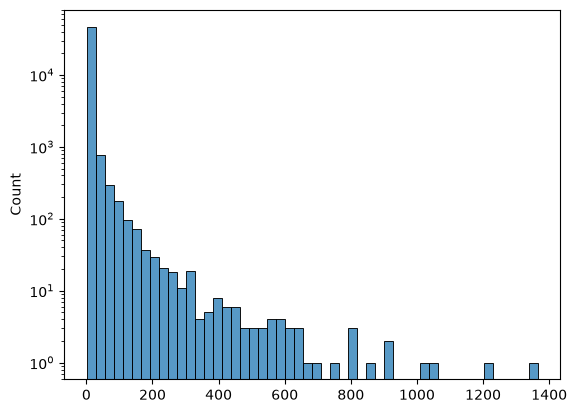

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot([token_count[token] for token in token_count], bins=50)
plt.yscale('log')

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

#### Answer:
The histogram is skewed right, so as the frequency of occurance increases, the number of tokens decreases. The small amount of tokens at the rightward tail of the histogram have a very high frequency while the majority of tokens have a relatively low frequency.

**Q2.** 

In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler



data = pd.read_parquet('data/Phishing_clean.parquet')
len(data)

#1.
X = data.drop(columns=["Email Type"])
Y = data["Email Type"]
classification_X_raw = data[["Email Type"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=50,
    stratify=Y,
)

#2.
model = LinearRegression()
model.fit(X_train, y_train)

print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

#3.
coefs = pd.Series(model.coef_, index=X_train.columns)
top = coefs[coefs.abs().nlargest(5).index]
print(top)




0.7687749746991981
0.6540676060978555
helvetica,           0.964489
background-image:   -0.816539
localized            0.753812
thermal              0.741281
none;               -0.623966
dtype: float64


**Q3.** 

[0.09, 0.07, 0.07, 0.06, 0.06, 0.06, 0.05, 0.05, 0.05, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.0

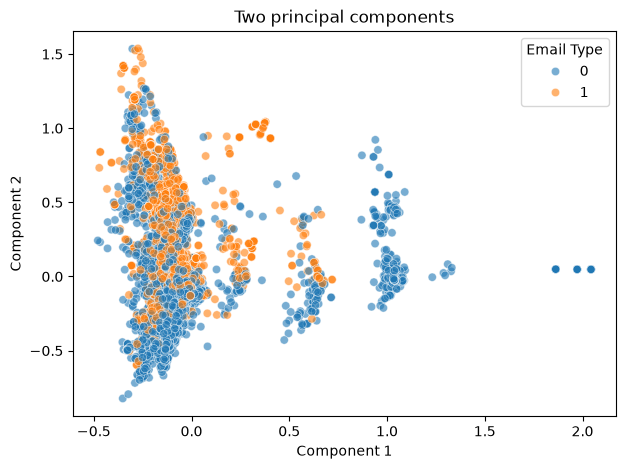

please    -0.109197
would     -0.089941
like      -0.089732
get       -0.067595
message   -0.049269
enron     -0.046540
email     -0.045669
call      -0.043308
know      -0.043171
dear      -0.041413
Name: Component 1, dtype: float64
failure      0.062330
schedule     0.062773
required     0.063315
schedules    0.194364
ancillary    0.194725
hourahead    0.255696
hour         0.260594
start        0.287437
url:         0.367390
date         0.674016
Name: Component 1, dtype: float64
please       -0.200660
message      -0.149039
call         -0.133802
attached     -0.133462
enron        -0.116282
conference   -0.100374
original     -0.094455
papers       -0.086622
university   -0.082093
see          -0.055564
Name: Component 2, dtype: float64
online       0.082438
available    0.082556
one          0.118190
software     0.127440
offer        0.136154
hello        0.144890
get          0.316850
would        0.318753
like         0.414520
new          0.451125
Name: Component 2, dtype: fl

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

X = data.drop(columns=["Email Type"])
y = data["Email Type"]

correlations = X.corr()
Z = X - X.mean()
C = (Z.T @ Z) / (len(Z) - 1)

eigenvalues, eigenvectors = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
print(eigenvalues.round(2).tolist())

L = 2
P = eigenvectors[:, :L]
X_pca = Z @ P
explained_ratio = eigenvalues / eigenvalues.sum()

print("Dimensions:", X.shape, X_pca.shape)
print("Variance retained:")

pca = PCA(n_components=L).fit(X)
X_pca_sklearn = pca.transform(X)
print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca.explained_variance_ratio_)
print("Manual: ", explained_ratio[:L])

pca_df = pd.DataFrame(X_pca.values, columns=["Component 1", "Component 2"])
pca_df["Email Type"] = y.values

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=pca_df, x="Component 1", y="Component 2",
    hue="Email Type", alpha=0.6
)
plt.title("Two principal components")
plt.xlabel(f"Component 1")
plt.ylabel(f"Component 2")
plt.show()

loadings = pd.DataFrame(P, index=X.columns, columns=["Component 1", "Component 2"])
print(loadings["Component 1"].sort_values().head(10))
print(loadings["Component 1"].sort_values().tail(10))
print(loadings["Component 2"].sort_values().head(10))
print(loadings["Component 2"].sort_values().tail(10))


#### Observations:

There appears to be clumps of data points, segmented by PC1. The main clump is between values of -0.5 and for PC1. Additionally, the email type 0 has higher values for PC1 whereas the email type 1 has lower values generally.

**Q4.**

In [28]:

k = 2610
pca = PCA(n_components=k)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)
pcr = LinearRegression().fit(Z_train, y_train)

print(pcr.score(Z_train, y_train))
print(pcr.score(Z_test, y_test))

0.7679184562778704
0.656088832799794


#### Observations:
The R^2 values on the training and test sets are very similar to those of the linear regression from earlier which makes sense given the sample size relative to the full size.

**Q5.**

#### Answer:
Using principle components instead of original data is more beneficial because it reduces any overfitting of the data since there is so many different pieces. Additionally, principle components are unrelated which is beneficial in that many tokens/words can be correlated to each other in specific contexts.

---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 8ccd36138a458c1947161801d9281c5e5b8e1374
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. 
We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
Plot a histogram of the occurrences of tokens. What do you notice about the frequency of occurrence of different tokens? How does it look?

2.
Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

3. 
Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

4.
Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1.
import pickle
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(len(token_count), "unique tokens;", len(all_tokens), "total tokens")
print(token_freq[:20])

counts = np.array([c for _, c in token_freq])

# Histogram of occurrence counts (how many tokens occur n times)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(counts, bins=50)
ax[0].set_title("Histogram of token occurrences")
ax[0].set_xlabel("Number of occurrences")
ax[0].set_ylabel("Number of distinct tokens")

# Same data on log-log axes, using log-spaced bins
bins = np.logspace(0, np.log10(counts.max()), 50)
ax[1].hist(counts, bins=bins)
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_title("Same histogram, log-log")
ax[1].set_xlabel("Number of occurrences (log)")
ax[1].set_ylabel("Number of distinct tokens (log)")

plt.tight_layout()
plt.show()

2.
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet("Phishing_clean.parquet")
y = df["Email Type"]
X = df.drop(columns=["Email Type"])

# 1. 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. OLS regression and R^2
# With 2,711 features, the design matrix may be rank-deficient.
# sklearn's LinearRegression uses lstsq and returns the minimum-norm solution.
ols = LinearRegression().fit(X_train, y_train)
print("Train R^2:", r2_score(y_train, ols.predict(X_train)))
print("Test  R^2:", r2_score(y_test,  ols.predict(X_test)))

# 3. Largest coefficients in absolute value
coefs = pd.Series(ols.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print(top.head(20))

3.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

data = pd.read_parquet("data/Phishing_clean.parquet")
X = data.drop(columns=["Email Type"])
y = data["Email Type"]

pca = PCA(n_components=2)
Z = pca.fit_transform(X)

print("Explained variance ratio:", pca.explained_variance_ratio_)

plot_df = pd.DataFrame({"PC1": Z[:, 0], "PC2": Z[:, 1],
                        "Phishing": y.map({0: "Not phishing", 1: "Phishing"})})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Phishing",
                alpha=0.5, s=15)
plt.title("First two principal components of email token matrix")
plt.show()

# Which words drive each component?
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
print(loadings["PC1"].abs().nlargest(10))
print(loadings["PC2"].abs().nlargest(10))

4.
from sklearn.linear_model import LinearRegression

data = pd.read_parquet("data/Phishing_clean.parquet")
X = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y
)

# Fit PCA on the training set only, then apply the same transform to test
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

print("Variance retained:", pca.explained_variance_ratio_.sum())

pcr = LinearRegression().fit(Z_train, y_train)
print("PCR train R^2:", pcr.score(Z_train, y_train))
print("PCR test  R^2:", pcr.score(Z_test, y_test))

# Baseline: OLS on the raw tokens, same split
ols = LinearRegression().fit(X_train, y_train)
print("OLS train R^2:", ols.score(X_train, y_train))
print("OLS test  R^2:", ols.score(X_test, y_test))

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The AI provided more visualizations that aided how the graphs were interpreted, so I decided to keep the suplemental work as it made it more visually appealing.
| 2 | Accept | It did the same thing that my code did but formatted it more nicely and in a more viually appealing manner.
| 3 | Reject | Again, it didn't really do anything new that my code didn't do; it just took up more space and added slightly more features. |
| 4 | Accept | It added more features including the comparion between the previous values and the new ones to compare side by side which was helpful. Additionally, it added words and their coefficients for additional context.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

48691 unique tokens; 276949 total tokens
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598)]


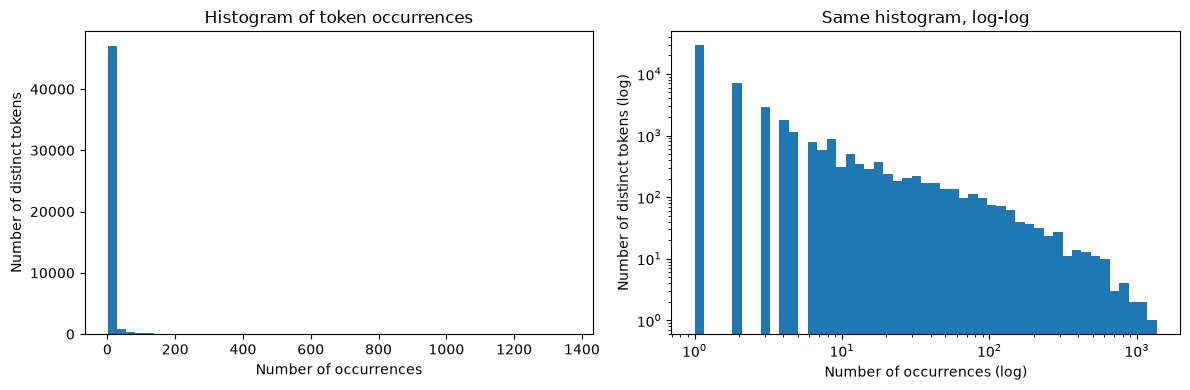

Train R^2: 0.7670143724934355
Test  R^2: 0.6658718438847921
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
shopper             -0.486678
april's             -0.486483
arial,              -0.482141
laser                0.473607
issue:              -0.465547
dtype: float64
Explained variance ratio: [0.01113086 0.00861219]


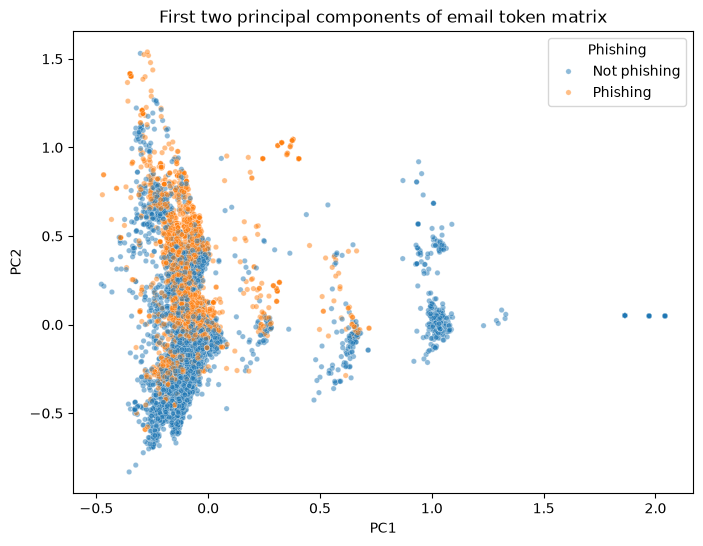

date         0.673929
url:         0.367338
start        0.287438
hour         0.260568
hourahead    0.255667
ancillary    0.194725
schedules    0.194365
please       0.109430
would        0.089739
like         0.089409
Name: PC1, dtype: float64
new         0.450967
like        0.414291
would       0.318437
get         0.316160
please      0.201166
message     0.150266
hello       0.144954
offer       0.135864
attached    0.135188
call        0.133864
Name: PC2, dtype: float64
Variance retained: 0.9998391369261741
PCR train R^2: 0.7679184562778704
PCR test  R^2: 0.656088832799794
OLS train R^2: 0.7687749746991981
OLS test  R^2: 0.6540676060978555


In [29]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

import seaborn as sns
import matplotlib.pyplot as plt

import pickle
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt


with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(len(token_count), "unique tokens;", len(all_tokens), "total tokens")
print(token_freq[:20])

counts = np.array([c for _, c in token_freq])

# Histogram of occurrence counts (how many tokens occur n times)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(counts, bins=50)
ax[0].set_title("Histogram of token occurrences")
ax[0].set_xlabel("Number of occurrences")
ax[0].set_ylabel("Number of distinct tokens")

# Same data on log-log axes, using log-spaced bins
bins = np.logspace(0, np.log10(counts.max()), 50)
ax[1].hist(counts, bins=bins)
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_title("Same histogram, log-log")
ax[1].set_xlabel("Number of occurrences (log)")
ax[1].set_ylabel("Number of distinct tokens (log)")

plt.tight_layout()
plt.show()


# 1. 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. OLS regression and R^2
# With 2,711 features, the design matrix may be rank-deficient.
# sklearn's LinearRegression uses lstsq and returns the minimum-norm solution.
ols = LinearRegression().fit(X_train, y_train)
print("Train R^2:", r2_score(y_train, ols.predict(X_train)))
print("Test  R^2:", r2_score(y_test,  ols.predict(X_test)))

# 3. Largest coefficients in absolute value
coefs = pd.Series(ols.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print(top.head(20))

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

data = pd.read_parquet("data/Phishing_clean.parquet")
X = data.drop(columns=["Email Type"])
y = data["Email Type"]

pca = PCA(n_components=2)
Z = pca.fit_transform(X)

print("Explained variance ratio:", pca.explained_variance_ratio_)

plot_df = pd.DataFrame({"PC1": Z[:, 0], "PC2": Z[:, 1],
                        "Phishing": y.map({0: "Not phishing", 1: "Phishing"})})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Phishing",
                alpha=0.5, s=15)
plt.title("First two principal components of email token matrix")
plt.show()

# Which words drive each component?
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
print(loadings["PC1"].abs().nlargest(10))
print(loadings["PC2"].abs().nlargest(10))

from sklearn.linear_model import LinearRegression

data = pd.read_parquet("data/Phishing_clean.parquet")
X = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y
)

# Fit PCA on the training set only, then apply the same transform to test
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

print("Variance retained:", pca.explained_variance_ratio_.sum())

pcr = LinearRegression().fit(Z_train, y_train)
print("PCR train R^2:", pcr.score(Z_train, y_train))
print("PCR test  R^2:", pcr.score(Z_test, y_test))

# Baseline: OLS on the raw tokens, same split
ols = LinearRegression().fit(X_train, y_train)
print("OLS train R^2:", ols.score(X_train, y_train))
print("OLS test  R^2:", ols.score(X_test, y_test))

### *Reflection on AI assistance
In your own words without generative AI.

Overall, the AI solutions were very similar to what I already had in terms of function though it went about each task in a different manner. Because of that, I didn't need some of its suggestions because what I had was already similar enough. However, as I have found with many other labs, the AI is really good at providing several perspectives of the same data. With this assignment particularly, I was confused initially why the AI results were giving different word outputs than mine, but I realized that it was the result of the "random_state" parameter being set at a differnet integer than the placeholder I used. Because of this, verification was a little more difficult, but the results generally lined up in terms of common types of words and some overlapping words based on the different randomized token selection groups. Lastly, the visualizations were also similar, so I felt confident about the AI results in comparison to my own.